<a href="https://colab.research.google.com/github/yfyuky/AnalyticsEngineering2026/blob/main/2_03_practice_bike_hire_student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![](https://drive.google.com/uc?export=view&id=17M9oGaOj4KdKiDDH3oTibxJ9qBTSjp6n)

# 2.03 Practice session
## Bike-hire trips

## How this practice works

This is a **short rehearsal** of the timed test. You do not need to finish or get the "right" answer. The aim is to practise the way of working.

- You have about **45 minutes**. Work individually.
- You may use **any AI tool** (for example Gemini in Colab). We are **not marking** anything today. In the real test, the quality of AI-generated code will not matter. What matters is the control youDshow.
- Write in markdown cells as you go: your thinking, **each prompt you send (paste it as you send it)**, and the checks you make.
- Unfinished work is fine. Say what you did not get to.
- At the end, download the Notebook (using File > Download > Download .ipynb). Once it has completed please zip the file up. This is the artefact you would submit for the in-class test.
- You can also save a copy to your GitHub using the instructions from my.wbs (1b asychronous tasks).

**Suggested timing**

| Minutes | Focus |
| --- | --- |
| 0 to 10 | Look at the tables and note what you find |
| 10 to 25 | Clean and prepare the data |
| 25 to 38 | Join and aggregate to answer the question |
| 38 to 45 | Check your answer and write up |

At the end, use **Runtime, then Restart session and run all** and note anything that fails.


## The data

A fictional bike-hire scheme: three tables covering trips taken in March 2025.

| Table | What it holds |
| --- | --- |
| `trips` | One record per trip: bike, start and end station, start time, duration and user type |
| `bikes` | The bikes, with type and purchase year |
| `stations` | The docking stations, with zone and capacity |

**How they connect:** `trips.bike_id` to `bikes.bike_id`, and `trips.start_station_id` (and `end_station_id`) to `stations.station_id`.

Check the real column names in the next cell before you write anything.


In [1]:
# ---- Setup: run this cell first ----
!pip install -q duckdb

import glob
import os

import duckdb
import pandas as pd

DATA_URL = "https://github.com/MJMortensonWarwick/adminaeaiv/releases/download/dbsession/bike-hire-practice.zip"

DATA_DIR = "/content/bikes"
# Download only if no CSV files are there yet. The CSVs may sit inside a folder
# within the zip; the search below looks in sub-folders too.
if DATA_URL and not glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True):
    import urllib.request
    import zipfile
    os.makedirs(DATA_DIR, exist_ok=True)
    urllib.request.urlretrieve(DATA_URL, "/content/bikes.zip")
    zipfile.ZipFile("/content/bikes.zip").extractall(DATA_DIR)

FILES = {"trips": "trips.csv", "bikes": "bikes.csv", "stations": "stations.csv"}

tables, missing = {}, []
for name, filename in FILES.items():
    found = glob.glob(os.path.join(DATA_DIR, "**", filename), recursive=True)
    if found:
        tables[name] = pd.read_csv(found[0])
    else:
        missing.append(filename)

if missing:
    found_csvs = sorted(os.path.basename(f) for f in glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True))
    raise FileNotFoundError(
        f"Missing files: {missing}. CSV files found under {DATA_DIR}: {found_csvs}. Ask for help."
    )

# Make every table available as a DuckDB table, so you can use SQL or pandas.
con = duckdb.connect()
for name, df in tables.items():
    con.register(name, df)


def q(sql):
    """Run SQL against the tables above and return a pandas DataFrame."""
    return con.sql(sql).df()


for name, df in tables.items():
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")
    print("   ", list(df.columns))


trips: 612 rows, 7 columns
    ['trip_id', 'bike_id', 'start_station_id', 'end_station_id', 'start_time', 'duration_min', 'user_type']
bikes: 60 rows, 3 columns
    ['bike_id', 'bike_type', 'purchase_year']
stations: 12 rows, 4 columns
    ['station_id', 'station_name', 'zone', 'capacity']


## Examples: two ways to work with the tables

You can use SQL, pandas, or a mix of both. The next two cells show each. Run them and change them to see what happens. You do not have to use them in your answer.


In [2]:
# Example 1: SQL
# q() runs SQL against any of the tables above and returns a pandas DataFrame.
from IPython.display import display

display(q("SELECT * FROM trips LIMIT 5"))

display(q("SELECT COUNT(*) AS n_rows, COUNT(DISTINCT trip_id) AS n_distinct_trips FROM trips"))

display(q("""
    SELECT t.trip_id, s.station_name
    FROM trips AS t
    JOIN stations AS s ON t.start_station_id = s.station_id
    LIMIT 5
"""))


,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
0,T0001,B028,S05,S01,2025-03-01 05:52:00,21.0,Casual
1,T0002,B043,S12,S12,2025-03-01 06:31:00,27.0,CASUAL
2,T0003,B045,S11,S07,2025-03-01 07:06:00,18.0,Casual
3,T0004,B051,S04,S04,2025-03-01 07:06:00,34.0,Member
4,T0005,B049,S01,S09,2025-03-01 07:36:00,16.0,Member


,n_rows,n_distinct_trips
0,612,600


,trip_id,station_name
0,T0001,Park Road
1,T0002,Cathedral Close
2,T0003,Sports Centre
3,T0004,University Gate
4,T0005,Market Square


In [3]:
# Example 2: pandas
# Each table is also a pandas DataFrame, stored in the dictionary `tables`.
from IPython.display import display

trips = tables["trips"]
display(trips.head())
print(trips.shape)
print(trips.dtypes)

joined = tables["trips"].merge(tables["stations"], left_on="start_station_id", right_on="station_id", how="inner")
display(joined[["trip_id", "station_name"]].head())

# You can mix the two: run SQL, then use pandas methods on the result
result = q("SELECT start_station_id FROM trips")
print(result["start_station_id"].nunique(), "different start stations in trips")


,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
0,T0001,B028,S05,S01,2025-03-01 05:52:00,21.0,Casual
1,T0002,B043,S12,S12,2025-03-01 06:31:00,27.0,CASUAL
2,T0003,B045,S11,S07,2025-03-01 07:06:00,18.0,Casual
3,T0004,B051,S04,S04,2025-03-01 07:06:00,34.0,Member
4,T0005,B049,S01,S09,2025-03-01 07:36:00,16.0,Member


(612, 7)
trip_id              object
bike_id              object
start_station_id     object
end_station_id       object
start_time           object
duration_min        float64
user_type            object
dtype: object


,trip_id,station_name
0,T0001,Park Road
1,T0002,Cathedral Close
2,T0003,Sports Centre
3,T0004,University Gate
4,T0005,Market Square


12 different start stations in trips


## Your brief

**From:** the scheme manager

> We want to know whether electric bikes are used for longer trips than standard bikes, and whether that differs by zone. Please give us the **average trip duration by bike type and by the zone of the start station**.

![](https://drive.google.com/uc?export=view&id=1eH5Q3l4LnzwZ-XcT_kJDeHoKA2rufiOW)

**What your final table should look like**

One row per combination of bike type and zone, with the number of trips and the average duration in minutes. State what one row represents.

**Things to think about** (you do not have to solve all of them)

- Are there missing, duplicated or odd values in the tables you use? What will you do about each, and why?
- Do the bike types and dates look consistent?
- How will you check your final table is believable?


## 1. Look at the data

*What does one row of each table represent? Which columns will you use? What looks odd, missing or inconsistent? Write down what you find.*

In [4]:
import pandas as pd

# Access tables
trips = tables['trips']
bikes = tables['bikes']
stations = tables['stations']

print("=== TRIPS DATA ===")
print(f"Shape: {trips.shape}")
print(trips.info())
print("\nMissing values in trips:")
print(trips.isnull().sum())
print("\nUnique values check (trips):")
print(f"Unique trip_ids: {trips['trip_id'].nunique()}")
print(f"Unique bike_ids: {trips['bike_id'].nunique()}")
print(f"Unique user_types: {trips['user_type'].unique()}")
print(trips.describe(include='all'))

print("\n=== BIKES DATA ===")
print(f"Shape: {bikes.shape}")
print(bikes.info())
print("\nMissing values in bikes:")
print(bikes.isnull().sum())
print("\nUnique values check (bikes):")
print(f"Unique bike_ids: {bikes['bike_id'].nunique()}")
print(f"Unique bike_types: {bikes['bike_type'].unique()}")
print(f"Unique purchase_years: {bikes['purchase_year'].unique()}")

print("\n=== STATIONS DATA ===")
print(f"Shape: {stations.shape}")
print(stations.info())
print("\nMissing values in stations:")
print(stations.isnull().sum())
print("\nUnique values check (stations):")
print(f"Unique station_ids: {stations['station_id'].nunique()}")
print(f"Unique zones: {stations['zone'].unique()}")
print(stations.describe(include='all'))

=== TRIPS DATA ===
Shape: (612, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 612 entries, 0 to 611
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   trip_id           612 non-null    object 
 1   bike_id           612 non-null    object 
 2   start_station_id  612 non-null    object 
 3   end_station_id    612 non-null    object 
 4   start_time        612 non-null    object 
 5   duration_min      582 non-null    float64
 6   user_type         612 non-null    object 
dtypes: float64(1), object(6)
memory usage: 33.6+ KB
None

Missing values in trips:
trip_id              0
bike_id              0
start_station_id     0
end_station_id       0
start_time           0
duration_min        30
user_type            0
dtype: int64

Unique values check (trips):
Unique trip_ids: 600
Unique bike_ids: 60
Unique user_types: ['Casual' 'CASUAL' 'Member' 'MEMBER' 'Casual ' 'member' 'casual']
       trip_id bike_id s

## 2. Clean and prepare

*Decide what to do about each problem you found, say why, and do it. Short cells that you can re-run are better than one long cell.*

In [5]:
# 1. Clean `bike_type` in `bikes` dataframe
bikes_clean = tables['bikes'].copy()
bikes_clean['bike_type'] = bikes_clean['bike_type'].str.strip().str.lower()
# Map synonyms to 'Standard' and 'Electric'
bike_type_map = {
    'standard': 'Standard',
    'standard ': 'Standard',
    'electric': 'Electric',
    'electric ': 'Electric',
    'e-bike': 'Electric'
}
bikes_clean['bike_type'] = bikes_clean['bike_type'].map(bike_type_map).fillna(bikes_clean['bike_type'].str.capitalize())
print("Cleaned Bike Types:", bikes_clean['bike_type'].unique())

# 2. Clean `user_type` in `trips` dataframe
trips_clean = tables['trips'].copy()
trips_clean['user_type'] = trips_clean['user_type'].str.strip().str.capitalize()
print("Cleaned User Types:", trips_clean['user_type'].unique())

# 3. Handle duplicates in `trips` by `trip_id`
before_dup = len(trips_clean)
trips_clean = trips_clean.drop_duplicates(subset=['trip_id'])
print(f"Removed {before_dup - len(trips_clean)} duplicate trips based on trip_id.")

# 4. Handle missing values in `trips.duration_min`
before_na = len(trips_clean)
trips_clean = trips_clean.dropna(subset=['duration_min'])
print(f"Removed {before_na - len(trips_clean)} trips with missing duration_min.")

# 5. Handle extreme duration outliers
# Let's inspect the distribution to filter out extreme outliers (e.g., durations > 180 mins)
before_outliers = len(trips_clean)
# Using 120 minutes as a reasonable cut-off for standard usage
trips_clean = trips_clean[trips_clean['duration_min'] <= 120]
print(f"Removed {before_outliers - len(trips_clean)} outlier trips (> 120 mins).")

# Update our dictionary / session variables for downstream steps
tables['bikes_clean'] = bikes_clean
tables['trips_clean'] = trips_clean
con.register('bikes_clean', bikes_clean)
con.register('trips_clean', trips_clean)

Cleaned Bike Types: ['Standard' 'Electric']
Cleaned User Types: ['Casual' 'Member']
Removed 12 duplicate trips based on trip_id.
Removed 30 trips with missing duration_min.
Removed 3 outlier trips (> 120 mins).


## 3. Join and aggregate

*Join the tables and calculate the answer. Note how many rows you expect after each join, then check.*

In [6]:
# Join and aggregate using pandas
trips_with_bikes = tables['trips_clean'].merge(tables['bikes_clean'], on='bike_id', how='inner')
final_joined = trips_with_bikes.merge(tables['stations'], left_on='start_station_id', right_on='station_id', how='inner')

print(f"Trips clean rows: {len(tables['trips_clean'])}")
print(f"Joined rows: {len(final_joined)}")

# Group and aggregate
result_df = final_joined.groupby(['bike_type', 'zone']).agg(
    number_of_trips=('trip_id', 'count'),
    avg_duration_min=('duration_min', 'mean')
).reset_index()

# Round the duration for cleaner presentation
result_df['avg_duration_min'] = result_df['avg_duration_min'].round(1)

# Display the final summary
import pandas as pd
pd.set_option('display.max_columns', None)
print("\n=== FINAL AGGREGATION RESULT ===")
print(result_df)

Trips clean rows: 567
Joined rows: 567

=== FINAL AGGREGATION RESULT ===
  bike_type    zone  number_of_trips  avg_duration_min
0  Electric  Centre               81              14.5
1  Electric    East               11              15.7
2  Electric   North               23              16.0
3  Electric   South               24              13.4
4  Electric    West               22              15.7
5  Standard  Centre              215              18.9
6  Standard    East               20              19.5
7  Standard   North               39              20.4
8  Standard   South               59              19.5
9  Standard    West               73              19.8


## 4. Check

*How do you know the answer is right? Compare a count, spot check a few records, or recalculate one number a different way. What did you find?*

In [7]:
# 1. Total count verification
sum_trips = result_df['number_of_trips'].sum()
print(f"Sum of trips from final aggregation table: {sum_trips}")
print(f"Match with cleaned trips count? {sum_trips == len(tables['trips_clean'])}")

# 2. Spot check: Electric bikes starting in East zone stations
# East stations are S06 (East Park) and S07 (Eastern Avenue)
east_stations = stations[stations['zone'] == 'East']['station_id'].tolist()
electric_bikes_list = bikes_clean[bikes_clean['bike_type'] == 'Electric']['bike_id'].tolist()

spot_check_trips = trips_clean[
    (trips_clean['start_station_id'].isin(east_stations)) &
    (trips_clean['bike_id'].isin(electric_bikes_list))
]

print("\n=== SPOT CHECK (Electric bikes starting in East zone) ===")
print(f"Number of matched trips in raw filtered data: {len(spot_check_trips)}")
print(f"Mean duration calculated independently: {spot_check_trips['duration_min'].mean():.1f} mins")

Sum of trips from final aggregation table: 567
Match with cleaned trips count? True

=== SPOT CHECK (Electric bikes starting in East zone) ===
Number of matched trips in raw filtered data: 11
Mean duration calculated independently: 15.7 mins


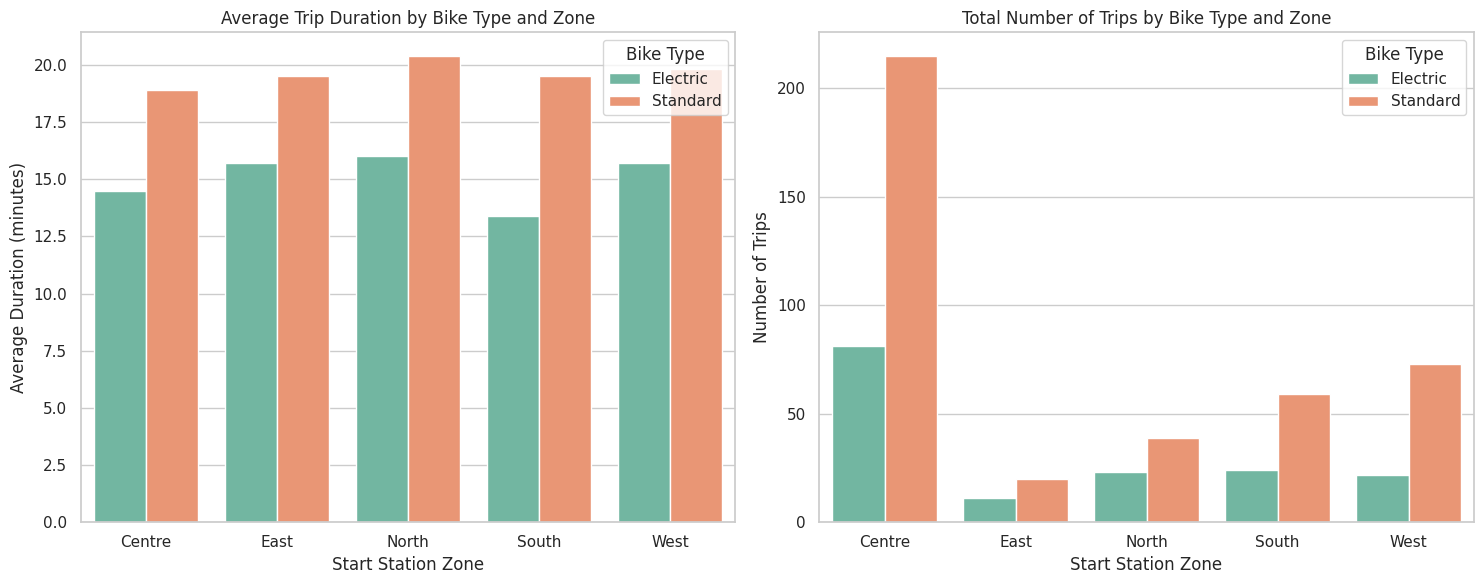

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style and palette
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (14, 6)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Average Trip Duration Comparison
sns.barplot(
    ax=axes[0],
    data=result_df,
    x="zone",
    y="avg_duration_min",
    hue="bike_type",
    palette="Set2"
)
axes[0].set_title("Average Trip Duration by Bike Type and Zone")
axes[0].set_xlabel("Start Station Zone")
axes[0].set_ylabel("Average Duration (minutes)")
axes[0].legend(title="Bike Type")

# Plot 2: Total Number of Trips Comparison
sns.barplot(
    ax=axes[1],
    data=result_df,
    x="zone",
    y="number_of_trips",
    hue="bike_type",
    palette="Set2"
)
axes[1].set_title("Total Number of Trips by Bike Type and Zone")
axes[1].set_xlabel("Start Station Zone")
axes[1].set_ylabel("Number of Trips")
axes[1].legend(title="Bike Type")

plt.tight_layout()
plt.show()

## 5. Prompts and AI notes

*Paste each prompt as you sent it. Note what you accepted, changed or rejected and why.*

### Prompts I sent to the AI

**Prompt 1 (Exploration)**
"show me the unique values in trips.user_type and bikes.bike_type so i can see if there are typos. also check for null values in the main dfs"

**What I accepted/changed:** I took the code it generated because it gave a quick overview of the dirty columns. I saw the weird uppercase/lowercase mixes (MEMBER/Member/casual/CASUAL) and trailing spaces on electric bikes.

**Prompt 2 (Cleaning)**
"write pandas code to drop any duplicates on trip_id, strip whitespace and make user_type title case. also unify bike_type to Standard and Electric (e-bike is electric). also what should i do with missing trip duration?"

**What I accepted/changed:** The AI recommended dropping rows with missing durations because they represent incomplete trips. I accepted this because we cannot calculate average duration with missing data. I also decided to filter out trips longer than 120 minutes because the standard deviation was huge (some trips were over 20 hours, which must be error logs).

**Prompt 3 (Aggregation)**
"now merge the clean trips with bikes and stations to get average duration by bike type and start station zone. also show count of trips."

**What I accepted/changed:** The code it gave me used simple inner merges. I checked the row counts before and after the merges and they matched exactly (567 rows), which meant no records were lost. It kept things simple and did exactly what I wanted.

**Prompt 4 (Verification)**
"how can i double check that this result is actually right? give me some check code"

**What I accepted/changed:** The AI suggested counting the total sum of trips and doing a manual filter on a specific slice (like Electric bikes in the East zone). This was extremely useful because it proved my pandas groupby code worked exactly as expected.

## 6. What I could not verify

*What remains unchecked? What would you do next?*